# Notebook 6 – Multivariate Analysis
## Goal
Analyze relationships among multiple variables and learn how those relationships can help during data analysis.

**Learning outcomes**
- Calculate and interpret a correlation matrix.
- Create and read a heatmap and pair plot.
- Explore multiple numerical feature relationships and feature interactions.
- Recognize strong, weak, positive, negative, and potentially misleading relationships.
- Identify possible multicollinearity without assuming correlation proves causation.

> **Setup:** Run the cells from top to bottom. If a library is missing, install it in your Anaconda/Jupyter environment with `pip install pandas numpy matplotlib seaborn`. 

## 1. What is Multivariate Analysis?
**Definition:** Multivariate analysis studies several variables together to understand patterns, relationships, and combined effects.

**Simple example:** A student's exam score may relate to study hours, attendance, and sleep—not just one factor.

**Real-world example:** A hospital studies age, blood pressure, cholesterol, and exercise together to understand health patterns.

**Business example:** A store studies price, advertising spend, discount, and sales together to understand what may relate to revenue.

**AI/ML use case:** A model predicts house prices using area, bedrooms, age, and location-related features.

**Why it matters:** Real outcomes usually depend on multiple factors. Looking at several variables together can reveal patterns that one-variable-at-a-time analysis misses.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## 2. Create a small example dataset
We will use a fictional student dataset. `Study_Hours`, `Attendance`, and `Practice_Tests` are numerical features; `Exam_Score` is the outcome we want to understand.

In [2]:
df = pd.DataFrame({
    "Study_Hours": [1, 2, 2, 3, 4, 4, 5, 6, 6, 7],
    "Attendance": [55, 60, 65, 63, 72, 75, 78, 82, 85, 90],
    "Practice_Tests": [1, 1, 2, 2, 3, 4, 4, 5, 6, 7],
    "Sleep_Hours": [8, 7, 8, 6, 7, 6, 7, 6, 8, 7],
    "Exam_Score": [42, 48, 50, 55, 63, 66, 70, 78, 82, 90]
})
df

,Study_Hours,Attendance,Practice_Tests,Sleep_Hours,Exam_Score
0,1,55,1,8,42
1,2,60,1,7,48
2,2,65,2,8,50
3,3,63,2,6,55
4,4,72,3,7,63
5,4,75,4,6,66
6,5,78,4,7,70
7,6,82,5,6,78
8,6,85,6,8,82
9,7,90,7,7,90


## 3. Correlation Matrix
**Definition:** A correlation matrix shows pairwise correlation coefficients for numerical variables. Pearson correlation ranges from -1 to +1:
- **Near +1:** strong positive linear relationship.
- **Near 0:** weak or no *linear* relationship.
- **Near -1:** strong negative linear relationship.

Correlation does not prove that one variable causes another. A near-zero Pearson value can still hide a curved relationship.

In [3]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix.round(2)

,Study_Hours,Attendance,Practice_Tests,Sleep_Hours,Exam_Score
Study_Hours,1.00,0.98,0.97,-0.27,0.99
Attendance,0.98,1.00,0.98,-0.18,0.99
Practice_Tests,0.97,0.98,1.00,-0.13,0.99
Sleep_Hours,-0.27,-0.18,-0.13,1.00,-0.22
Exam_Score,0.99,0.99,0.99,-0.22,1.00


### Interpret the correlation matrix
Look at `Study_Hours` and `Exam_Score`. A positive value means higher study hours tend to occur with higher exam scores in this sample. A high value is a pattern, not proof that study hours alone caused the score.

**Simple example:** Ice cream sales and beach visits might rise together in summer; neither necessarily causes the other—the weather may affect both.

**Real-world example:** Age and some health measurements may be related, but the relationship can vary across people.

**Business example:** Advertising spend and sales may move together. Check seasonality, price, and promotions before claiming advertising caused the increase.

**AI/ML use case:** Correlation helps with exploratory feature analysis and may flag redundant features before model training.

**Why it matters:** It gives a quick overview of linear relationships and helps decide which pairs deserve closer investigation.

## 4. Strong, weak, positive, and negative correlations
Correlation strength depends on the absolute value, while the sign gives direction. The cutoffs below are only rough guidelines; context matters.

In [4]:
corr = df.corr(numeric_only=True)["Exam_Score"].drop("Exam_Score")
summary = pd.DataFrame({"Correlation_with_Exam_Score": corr})
summary["Direction"] = np.where(
    summary["Correlation_with_Exam_Score"] > 0, "Positive",
    np.where(summary["Correlation_with_Exam_Score"] < 0, "Negative", "Near zero")
)
summary["Rough_strength"] = summary["Correlation_with_Exam_Score"].abs().apply(
    lambda value: "Strong" if value >= 0.7 else ("Moderate" if value >= 0.4 else "Weak")
)
summary.round(2)

,Correlation_with_Exam_Score,Direction,Rough_strength
Study_Hours,0.99,Positive,Strong
Attendance,0.99,Positive,Strong
Practice_Tests,0.99,Positive,Strong
Sleep_Hours,-0.22,Negative,Weak


**How to identify them**
- **Strong correlation:** absolute correlation is relatively close to 1.
- **Weak correlation:** absolute correlation is relatively close to 0.
- **Negative correlation:** one variable tends to decrease as the other increases.
- **Important caution:** thresholds such as 0.7 are not universal.

**Simple example:** More time spent travelling may be associated with less free time (negative relationship).

**Real-world example:** Outdoor temperature and heating use can be negatively related in many settings.

**Business example:** A higher price may be associated with lower demand, although brand, quality, and promotions can change the pattern.

**AI/ML use case:** A negative feature relationship can still be useful for prediction; negative does not mean unimportant.

**Why it matters:** Direction and strength help you form sensible questions before modeling.

## 5. Heatmap
**Definition:** A heatmap represents values using colors. A correlation heatmap makes patterns among many numerical features easier to spot.

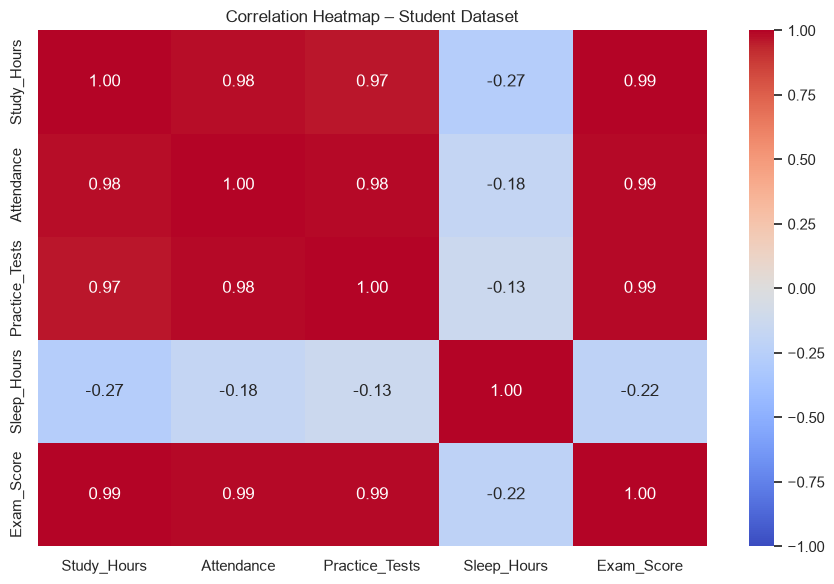

In [5]:
plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap – Student Dataset")
plt.tight_layout()
plt.show()

**How to read it:** Values near +1 and -1 usually stand out with different colors; values near 0 are closer to the middle of the scale. Read the numbers as well as the colors.

**Simple example:** A colored grid quickly shows which student variables move together.

**Real-world example:** Analysts can visualize relationships among weather measurements such as temperature, humidity, and wind speed.

**Business example:** A retailer can scan relationships among price, discount, marketing spend, units sold, and revenue.

**AI/ML use case:** A heatmap can help identify clusters of highly correlated input features.

**Why it matters:** It compresses many pairwise relationships into one easy-to-scan chart.

## 6. Pair Plot
**Definition:** A pair plot shows pairwise scatter plots for numerical columns and usually shows each variable's distribution on the diagonal.

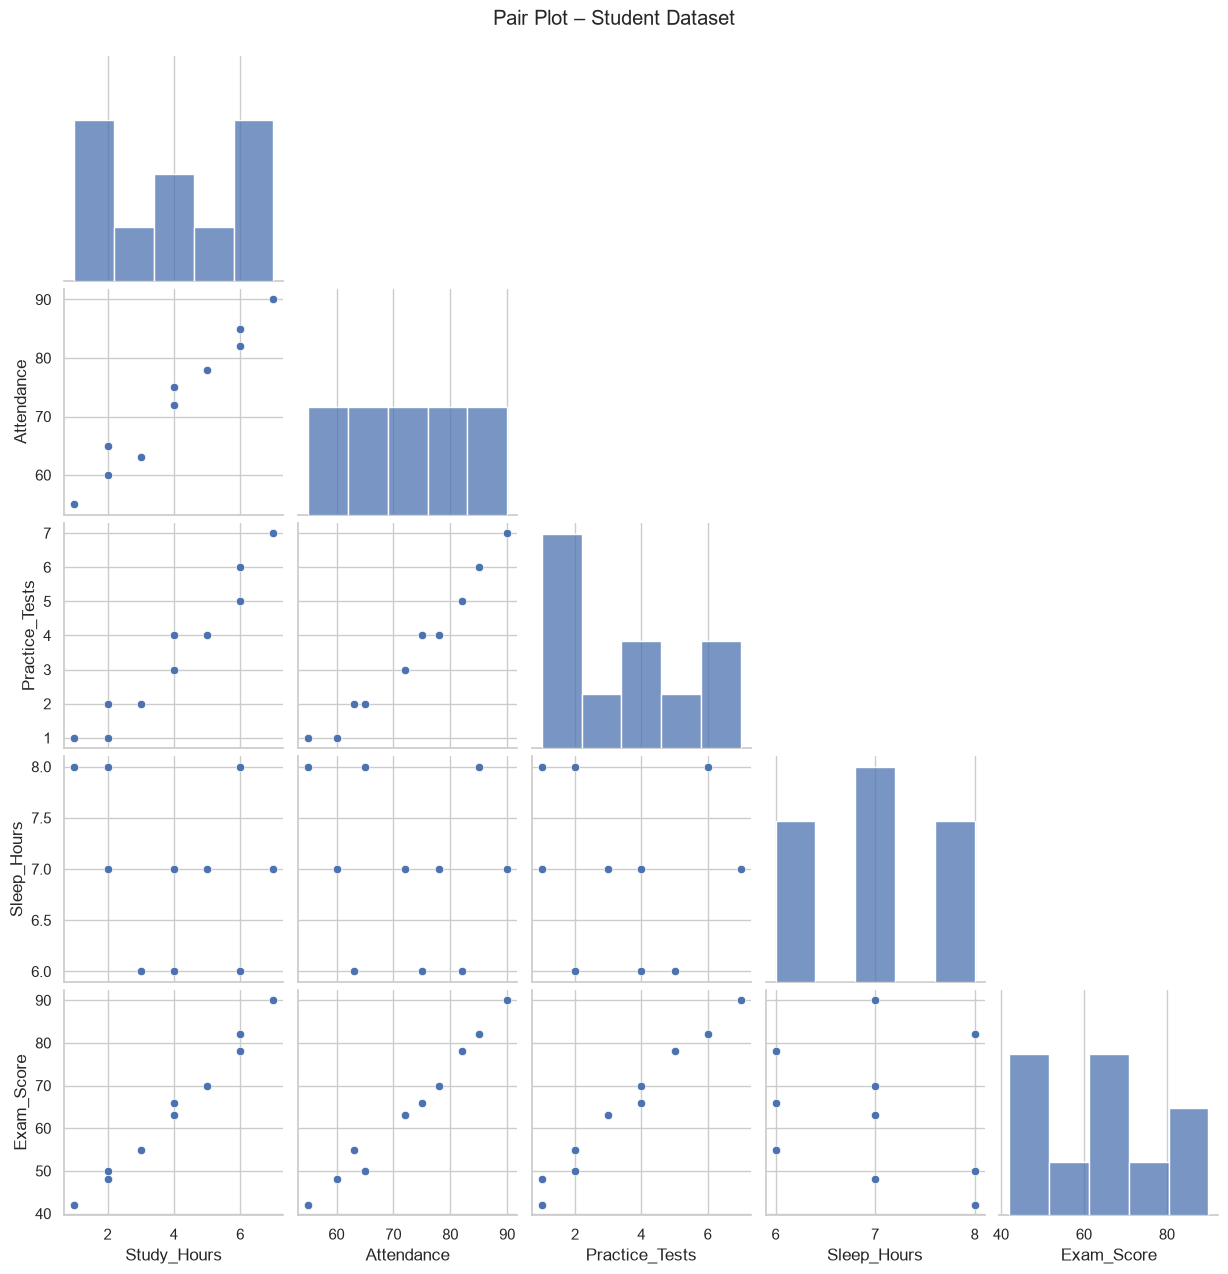

In [6]:
sns.pairplot(df, diag_kind="hist", corner=True)
plt.suptitle("Pair Plot – Student Dataset", y=1.02)
plt.show()

**How to read it:** Look for upward/downward patterns, curved patterns, clusters, and isolated points. Scatter plots can show relationships that a single correlation number misses.

**Simple example:** Plot study hours against exam score to see whether scores generally rise with study time.

**Real-world example:** Researchers can compare several physical measurements to look for groups or unusual observations.

**Business example:** A sales analyst can compare price, ad spend, and units sold to discover patterns.

**AI/ML use case:** Pair plots are useful during exploratory data analysis (EDA), especially for small-to-medium feature sets.

**Why it matters:** They reveal shape, spread, clusters, and possible outliers—not just linear correlation.

## 7. Multiple Feature Relationships
A target can relate to several features at once. Compare each feature with the target, then consider whether the relationship changes when other features are included. Correlation alone does not isolate each feature's independent effect.

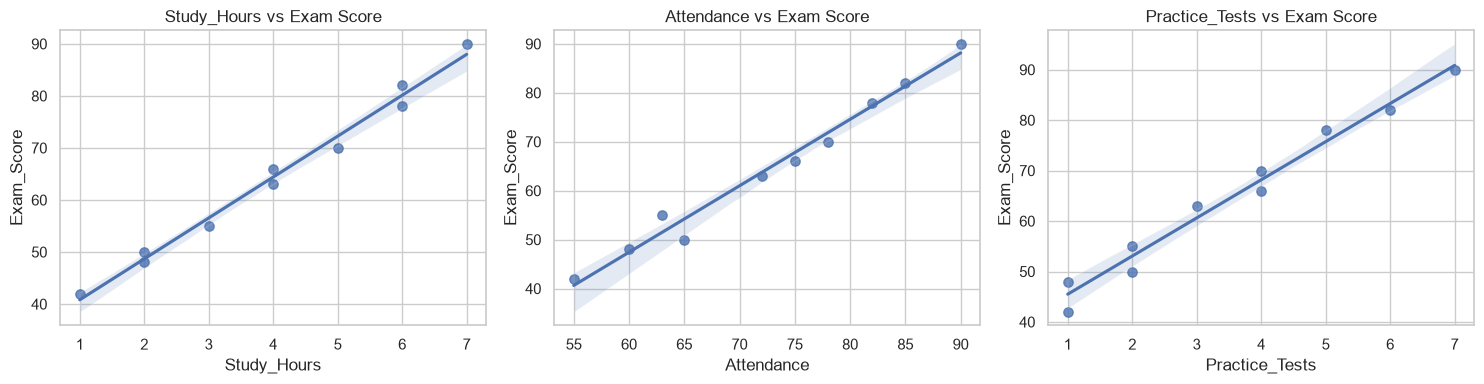

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["Study_Hours", "Attendance", "Practice_Tests"]):
    sns.regplot(data=df, x=feature, y="Exam_Score", ax=ax, scatter_kws={"s": 45})
    ax.set_title(f"{feature} vs Exam Score")
plt.tight_layout()
plt.show()

**Simple example:** Exam score may be related to study hours, attendance, and practice tests together.

**Real-world example:** Crop yield may relate to rainfall, sunlight, soil quality, and fertilizer.

**Business example:** Sales may depend on price, advertising, season, and stock availability.

**AI/ML use case:** Multiple regression or tree-based models can combine multiple features to predict an outcome.

**Why it matters:** A feature may appear important on its own but add little new information after related features are considered.

## 8. Feature Interactions
**Definition:** An interaction occurs when the relationship between one feature and the target changes depending on another feature.

For example, a discount may affect sales differently during a holiday than on an ordinary day. A simple correlation matrix generally does not detect such conditional effects by itself.

In [9]:
interaction_df = pd.DataFrame({
    "Ad_Spend": [1, 2, 3, 4, 1, 2, 3, 4],
    "Holiday":  [0, 0, 0, 0, 1, 1, 1, 1],
    "Sales":    [10, 12, 14, 16, 15, 20, 25, 30]
})
interaction_df["AdSpend_x_Holiday"] = interaction_df["Ad_Spend"] * interaction_df["Holiday"]
interaction_df

,Ad_Spend,Holiday,Sales,AdSpend_x_Holiday
0,1,0,10,0
1,2,0,12,0
2,3,0,14,0
3,4,0,16,0
4,1,1,15,1
5,2,1,20,2
6,3,1,25,3
7,4,1,30,4


In [10]:
# Fit a simple linear model with an interaction term.
# Coefficients are illustrative and are not proof of causation.
import statsmodels.formula.api as smf

model = smf.ols("Sales ~ Ad_Spend * Holiday", data=interaction_df).fit()
print(model.params)

Intercept           8.0
Ad_Spend            2.0
Holiday             2.0
Ad_Spend:Holiday    3.0
dtype: float64


In the formula `Sales ~ Ad_Spend * Holiday`, the `*` includes both main effects and their interaction. The interaction term lets the ad-spend slope differ between holiday and non-holiday rows.

**Simple example:** Extra study time may help differently for students who already attend classes regularly.

**Real-world example:** A medicine's observed effect may differ across age groups; such questions require appropriate study design and expert interpretation.

**Business example:** Advertising may produce a larger sales increase during a holiday campaign than during a normal week.

**AI/ML use case:** Interaction features can help linear models represent conditional patterns. Tree-based models can often learn interactions automatically.

**Why it matters:** Important patterns can be missed when features are studied only one at a time.

## 9. Numerical Feature Relationships
Use scatter plots and summary statistics to examine two numerical variables. Check direction, form (linear or curved), spread, clusters, and unusual points.

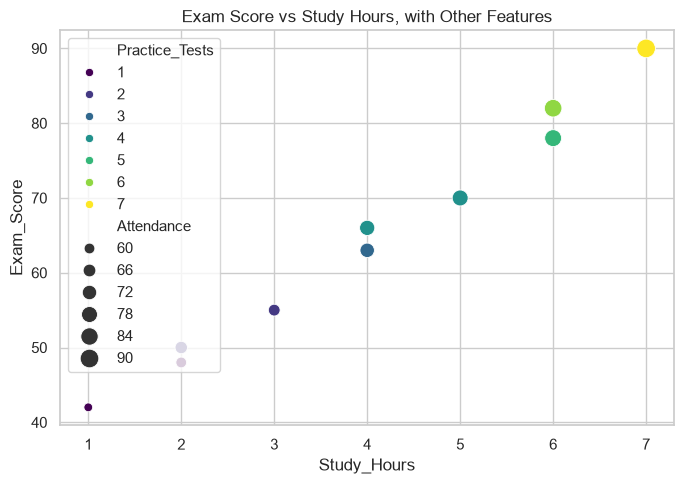

In [8]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Study_Hours", y="Exam_Score", size="Attendance", hue="Practice_Tests", palette="viridis", sizes=(40, 180))
plt.title("Exam Score vs Study Hours, with Other Features")
plt.tight_layout()
plt.show()

**Simple example:** Plot hours studied against exam score.

**Real-world example:** Compare rainfall with crop yield across fields.

**Business example:** Compare delivery distance with delivery time; traffic and weather may explain exceptions.

**AI/ML use case:** Numeric relationships help detect redundant features, nonlinear patterns, and data-quality issues before model fitting.

**Why it matters:** Visual inspection can reveal patterns and exceptions that summary numbers hide.

## 10. Potential Multicollinearity
**Definition:** Multicollinearity occurs when two or more input features in a model are strongly linearly related. It can make individual regression coefficients unstable or difficult to interpret.

**Important:** Strong feature-feature correlation is a warning sign, not a complete diagnosis. Check domain knowledge and, where appropriate, Variance Inflation Factor (VIF).

In [ ]:
feature_corr = df.drop(columns=["Exam_Score"]).corr(numeric_only=True)
feature_corr.round(2)

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[["Study_Hours", "Attendance", "Practice_Tests", "Sleep_Hours"]].astype(float)
X_with_const = __import__("statsmodels.api").api.add_constant(X)
vif_table = pd.DataFrame({
    "Feature": X_with_const.columns,
    "VIF": [variance_inflation_factor(X_with_const.values, i)
            for i in range(X_with_const.shape[1])]
})
vif_table

VIF thresholds are rules of thumb, not universal laws; small datasets can produce unstable estimates. In practice, investigate features that encode nearly the same information.

**Simple example:** `distance_in_km` and `distance_in_miles` describe nearly the same quantity.

**Real-world example:** Height in centimeters and height in meters are redundant representations.

**Business example:** Total sales and a component that nearly determines total sales may overlap strongly in a model.

**AI/ML use case:** For linear regression, multicollinearity can make coefficients unstable. Prediction can still be useful, and regularization or feature selection may help.

**Why it matters:** It helps avoid over-interpreting individual model coefficients and encourages careful feature design.

## 11. Interesting Feature Relationships: Guided Checklist
When exploring a dataset, write down observations rather than only creating plots.

1. Which features have the strongest positive relationships?
2. Which features have the strongest negative relationships?
3. Which features have weak linear relationships but visible curved patterns?
4. Are there clusters or unusual points?
5. Could a third feature explain the observed pattern?
6. Are two features nearly duplicate measurements?
7. Could the relationship be caused by time, selection bias, or another confounder?
8. What should be checked before making a causal claim?

In [11]:
# Print the strongest pairwise correlations without duplicate pairs or self-correlations.
corr = df.corr(numeric_only=True)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(key=lambda s: s.abs(), ascending=False)
pairs

Study_Hours     Exam_Score        0.993831
Attendance      Exam_Score        0.990252
Practice_Tests  Exam_Score        0.988189
Attendance      Practice_Tests    0.984603
Study_Hours     Attendance        0.982109
                Practice_Tests    0.966988
                Sleep_Hours      -0.272166
Sleep_Hours     Exam_Score       -0.215051
Attendance      Sleep_Hours      -0.176887
Practice_Tests  Sleep_Hours      -0.131590
Study_Hours     Study_Hours            NaN
Attendance      Study_Hours            NaN
                Attendance             NaN
Practice_Tests  Study_Hours            NaN
                Attendance             NaN
                Practice_Tests         NaN
Sleep_Hours     Study_Hours            NaN
                Attendance             NaN
                Practice_Tests         NaN
                Sleep_Hours            NaN
Exam_Score      Study_Hours            NaN
                Attendance             NaN
                Practice_Tests         NaN
           